In [4]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
# Load dataset
df = pd.read_csv("uber.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [6]:
# Preprocessing
df = df.dropna()
df = df.drop(['Unnamed: 0', 'key'], axis=1)

In [7]:
# Convert datetime and extract features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

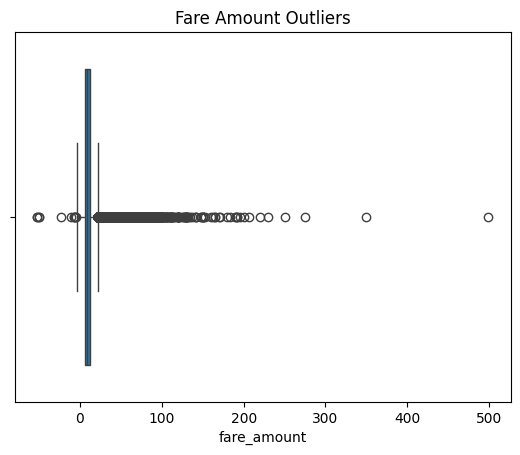

In [8]:
# Identify outliers using boxplot
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()

In [9]:
# Calculate Euclidean distance
df['distance'] = np.sqrt(
    (df['dropoff_latitude'] - df['pickup_latitude'])**2 +
    (df['dropoff_longitude'] - df['pickup_longitude'])**2
)

In [ ]:
# Remove invalid values
df = df[
    (df['fare_amount'] > 0) &
    (df['fare_amount'] < 100) &
    (df['passenger_count'] > 0) &
    (df['passenger_count'] <= 6) &
    (df['pickup_latitude'] != 0) &
    (df['pickup_longitude'] != 0) &
    (df['dropoff_latitude'] != 0) &
    (df['dropoff_longitude'] != 0)
]

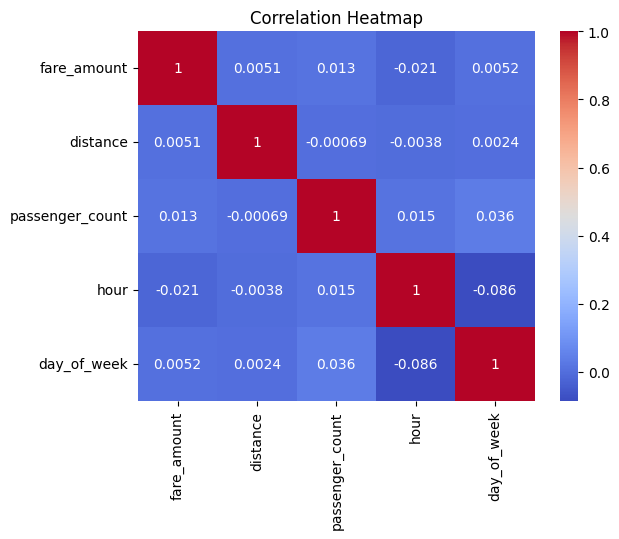

In [17]:
# Correlation heatmap
corr = df[['fare_amount', 'distance', 'passenger_count',
           'hour', 'day_of_week']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [12]:
# Features and target
X = df[['distance', 'passenger_count', 'hour', 'day_of_week']]
y = df['fare_amount']

In [13]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [15]:
# Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [13]:
# Evaluation
def evaluate(y_test, y_pred, name):
    print(name)
    print("R2 Score:", r2_score(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest")

Linear Regression
R2 Score: 0.0006550889372549662
RMSE: 9.419859095720144
Random Forest
R2 Score: 0.7652541750108235
RMSE: 4.565471567176098
